In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
airport_columns = [
    "Airport_ID", "Name", "City", "Country", "IATA", "ICAO",
    "Latitude", "Longitude", "Altitude", "Timezone",
    "DST", "Tz_database", "Type", "Source"
]

airports = pd.read_csv(
    "airports.dat",
    header=None,
    names=airport_columns
)

print("Airport dataset shape:", airports.shape)
airports.head()

Airport dataset shape: (7698, 14)


,Airport_ID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,Tz_database,Type,Source
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998,5282,10,U,Pacific/Port_Moresby,airport,OurAirports
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001,20,10,U,Pacific/Port_Moresby,airport,OurAirports
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005,5388,10,U,Pacific/Port_Moresby,airport,OurAirports
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977,239,10,U,Pacific/Port_Moresby,airport,OurAirports
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001,146,10,U,Pacific/Port_Moresby,airport,OurAirports


In [4]:
route_columns = [
    "Airline", "Airline_ID",
    "Source_Airport", "Source_Airport_ID",
    "Destination_Airport", "Destination_Airport_ID",
    "Codeshare", "Stops", "Equipment"
]

routes = pd.read_csv(
    "routes.dat",
    header=None,
    names=route_columns
)

print("Routes dataset shape:", routes.shape)
routes.head()

Routes dataset shape: (67663, 9)


,Airline,Airline_ID,Source_Airport,Source_Airport_ID,Destination_Airport,Destination_Airport_ID,Codeshare,Stops,Equipment
0,2B,410,AER,2965,KZN,2990,NaN,0,CR2
1,2B,410,ASF,2966,KZN,2990,NaN,0,CR2
2,2B,410,ASF,2966,MRV,2962,NaN,0,CR2
3,2B,410,CEK,2968,KZN,2990,NaN,0,CR2
4,2B,410,CEK,2968,OVB,4078,NaN,0,CR2


In [5]:
zimbabwe_airports = airports[
    airports["Country"].str.strip().str.lower() == "zimbabwe"
].copy()

print("Number of Zimbabwe airports:", len(zimbabwe_airports))

zimbabwe_airports[
    ["Airport_ID", "Name", "City", "IATA", "ICAO", "Latitude", "Longitude"]
]

Number of Zimbabwe airports: 16


,Airport_ID,Name,City,IATA,ICAO,Latitude,Longitude
978,1001,Joshua Mqabuko Nkomo International Airport,Bulawayo,BUQ,FVBU,-20.017401,28.617901
979,1002,Charles Prince Airport,Harare,\N,FVCP,-17.751600,30.924700
980,1003,Buffalo Range Airport,Chiredzi,BFO,FVCZ,-21.008101,31.578600
981,1004,Victoria Falls International Airport,Victoria Falls,VFA,FVFA,-18.095900,25.839001
982,1005,Robert Gabriel Mugabe International Airport,Harare,HRE,FVHA,-17.931801,31.092800
983,1006,Kariba International Airport,Kariba,KAB,FVKB,-16.519800,28.885000
984,1007,Mutoko Airport,Mutoko,\N,FVMT,-17.431900,32.184502
985,1008,Mutare Airport,Mutare,UTA,FVMU,-18.997499,32.627201
986,1009,Masvingo International Airport,Masvingo,MVZ,FVMV,-20.055300,30.859100
987,1010,Zvishavane Airport,Zvishavane,\N,FVSH,-20.289499,30.088200


In [6]:
zim_iata = set(
    zimbabwe_airports["IATA"]
    .replace("\\N", pd.NA)
    .dropna()
)

zim_routes = routes[
    routes["Source_Airport"].isin(zim_iata) |
    routes["Destination_Airport"].isin(zim_iata)
].copy()

print("Zimbabwe airports with IATA codes:", len(zim_iata))
print("Routes involving Zimbabwe:", len(zim_routes))
print()

zim_routes[
    ["Airline", "Source_Airport", "Destination_Airport", "Stops", "Equipment"]
].head(20)

Zimbabwe airports with IATA codes: 11
Routes involving Zimbabwe: 73



,Airline,Source_Airport,Destination_Airport,Stops,Equipment
8996,AF,AMS,HRE,0,332
9574,AF,HRE,LUN,0,763 332 330
9575,AF,HRE,NBO,0,E90
9673,AF,LUN,HRE,0,E90
9677,AF,LVI,HRE,0,E90
9785,AF,NBO,HRE,0,763
14551,BA,HRE,JNB,0,734 733
14576,BA,JNB,HRE,0,734 733
14581,BA,JNB,VFA,0,734
14923,BA,VFA,JNB,0,734


In [7]:
# Build a directed graph of routes involving Zimbabwe
G = nx.DiGraph()

for _, row in zim_routes.iterrows():
    source = row["Source_Airport"]
    destination = row["Destination_Airport"]

    if pd.notna(source) and pd.notna(destination):
        G.add_edge(source, destination)

print("Number of airports (nodes):", G.number_of_nodes())
print("Number of route connections (edges):", G.number_of_edges())

print("\nAirports in the network:")
print(sorted(G.nodes()))

Number of airports (nodes): 16
Number of route connections (edges): 35

Airports in the network:
['ADD', 'AMS', 'BUQ', 'DAR', 'DUR', 'GBE', 'HRE', 'JNB', 'LAD', 'LLW', 'LUN', 'LVI', 'MUB', 'NBO', 'VFA', 'WDH']


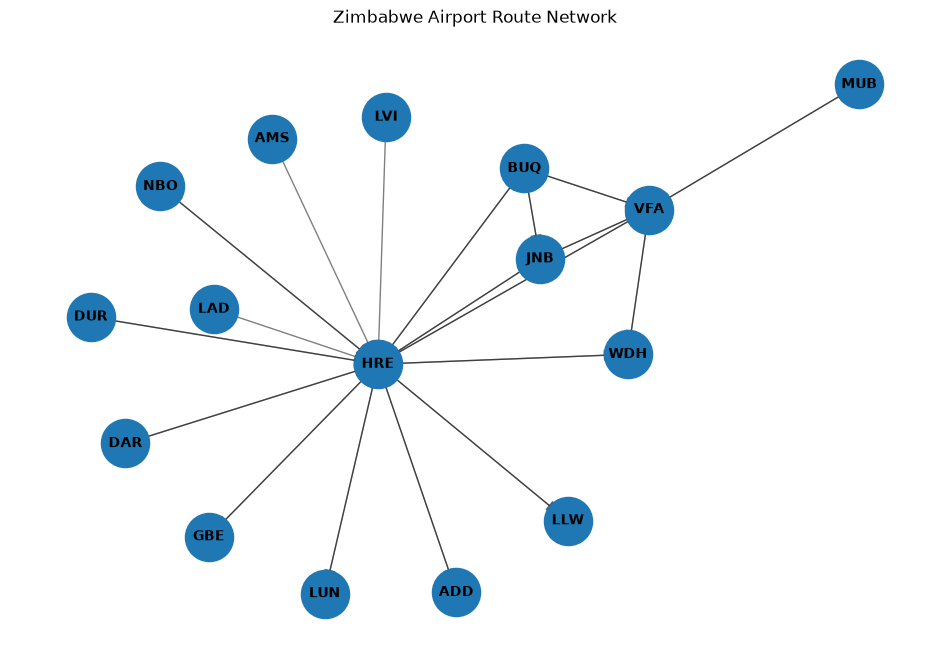

In [8]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=1200
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=18,
    alpha=0.5
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold"
)

plt.title("Zimbabwe Airport Route Network")
plt.axis("off")
plt.show()

In [9]:
# Calculate degree centrality
degree_centrality = nx.degree_centrality(G)

centrality_df = pd.DataFrame(
    degree_centrality.items(),
    columns=["Airport", "Degree_Centrality"]
)

centrality_df = centrality_df.sort_values(
    by="Degree_Centrality",
    ascending=False
).reset_index(drop=True)

centrality_df.head(10)

,Airport,Degree_Centrality
0,HRE,1.666667
1,VFA,0.666667
2,JNB,0.400000
3,BUQ,0.400000
4,WDH,0.266667
5,NBO,0.133333
6,GBE,0.133333
7,LUN,0.133333
8,DUR,0.133333
9,DAR,0.133333


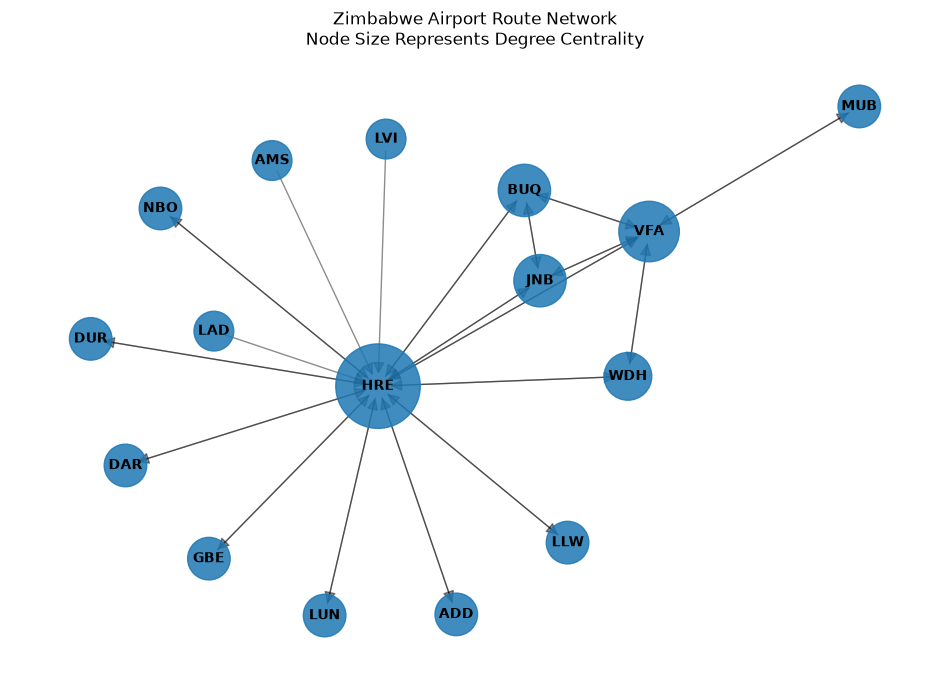

In [10]:
# Scale node sizes using degree centrality
node_sizes = [
    700 + (degree_centrality[node] * 1800)
    for node in G.nodes()
]

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    alpha=0.85
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=18,
    alpha=0.45
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold"
)

plt.title(
    "Zimbabwe Airport Route Network\n"
    "Node Size Represents Degree Centrality"
)

plt.axis("off")
plt.show()

In [11]:
# Calculate betweenness centrality
betweenness = nx.betweenness_centrality(G)

betweenness_df = pd.DataFrame(
    betweenness.items(),
    columns=["Airport", "Betweenness_Centrality"]
)

betweenness_df = betweenness_df.sort_values(
    by="Betweenness_Centrality",
    ascending=False
).reset_index(drop=True)

betweenness_df.head(10)

,Airport,Betweenness_Centrality
0,HRE,0.714286
1,VFA,0.128571
2,LUN,0.000000
3,AMS,0.000000
4,NBO,0.000000
5,LVI,0.000000
6,JNB,0.000000
7,GBE,0.000000
8,LAD,0.000000
9,ADD,0.000000


In [12]:
network_metrics = centrality_df.merge(
    betweenness_df,
    on="Airport"
)

network_metrics = network_metrics.sort_values(
    "Degree_Centrality",
    ascending=False
).reset_index(drop=True)

network_metrics.head(10)

,Airport,Degree_Centrality,Betweenness_Centrality
0,HRE,1.666667,0.714286
1,VFA,0.666667,0.128571
2,JNB,0.400000,0.000000
3,BUQ,0.400000,0.000000
4,WDH,0.266667,0.000000
5,NBO,0.133333,0.000000
6,GBE,0.133333,0.000000
7,LUN,0.133333,0.000000
8,DUR,0.133333,0.000000
9,DAR,0.133333,0.000000


In [13]:
airline_columns = [
    "Airline_ID",
    "Name",
    "Alias",
    "IATA",
    "ICAO",
    "Callsign",
    "Country",
    "Active"
]

airlines = pd.read_csv(
    "airlines.dat",
    header=None,
    names=airline_columns
)

print("Airlines dataset shape:", airlines.shape)

airlines[
    airlines["IATA"].isin(["EK", "ET", "BA", "QR", "AF"])
][["Name", "IATA", "ICAO", "Country", "Active"]]

Airlines dataset shape: (6162, 8)


,Name,IATA,ICAO,Country,Active
137,Air France,AF,AFR,France,Y
1354,British Airways,BA,BAW,United Kingdom,Y
2182,Emirates,EK,UAE,United Arab Emirates,Y
2219,Ethiopian Airlines,ET,ETH,Ethiopia,Y
4085,Qatar Airways,QR,QTR,Qatar,Y
